# Recumbent fold

First notebook in this paper series. It introduces the two ways we build
geology from contacts and orientations: a **direct scalar interpolant**
(`strati` + FSF) and a **diffeomorphic restore** event. Later notebooks reuse
the same `CSet` / `HSet` objects, `figstyle`, and event constructors on
harder geometries (refolds, analogue models, 3-D volumes).

**Why this example.** A recumbent fold has an overturned limb. From the same
two horizons and two bedding normals, implicit interpolation typically
collapses to a closed pod — a single-valued scalar field cannot represent
the fold. Restore can, because lithology is a flat layer-cake pulled back
through a divergence-free flow (`div v = 0`).

**Data.** The synthetic fold pair made by `01a_recumbent_fold_data`: drillholes
sample the contacts and the bedding and miss the bends, so a smooth scalar fit
bubbles. Both fits are scored against the true units. Saved under `results/synthetic/`.

**What this notebook is.** Computation and diagnostics only. It fits the
direct scalar interpolant (NF) and the diffeomorphic restore (LDI), and plots
quick checks that are *not* saved. What is saved, to
`results/<DATASET>/`, is everything the publication
notebook needs:

- `inputs.npz` — contacts, normals and the evaluation grid (also read by
  `01c_recumbent_fold_surfe`, so Surfe is run on exactly the same grid)
- `nf.npz`, `ldi.npz` — fitted scalar, lithology and critical points on that grid
  (LDI also stores the deformed paleo grid)
- `nf_field.pt`, `ldi_field.pt` — fitted field parameters
The final figures are made in `01e_recumbent_fold_figures.ipynb`.

One fit per method, with one Fourier seed. The Fourier-seed ensembles are in
`01d_recumbent_fold_ensemble`, which reads this notebook's `fit_settings.json`.


## Setup

`figstyle.apply()` installs the plotting defaults used by every paper figure
(see `figstyle.py`). Work in 2-D (`curlew.default_dim = 2`) on the `x`–`z`
section. Coordinates are shifted to the data centroid next so the Fourier
features stay well conditioned in `float32`.


In [1]:
# Pathing and general imports
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, Normalize

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
figstyle.apply()

# Reload local plotting/analysis helpers during interactive notebook work.
import importlib
importlib.reload(diagnostics)

# Import all necessary curlew modules
import curlew
from curlew.core import CSet, HSet
from curlew.geometry import Grid
from curlew.fields.series import FSF
from curlew.geology import restore, strati
from curlew.kinematics.euler import EulerVelocity, euler_velocity
from curlew.priors.spectral import spectral_band, n_features_for_band
from curlew.kinematics.training import SpectralWarmup
from tqdm import tqdm
import cmasher as cmr

# Set device and precision
curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

# Set seed for reproducibility
SEED = 404
random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"device={curlew.device}, dtype={curlew.dtype}")
print(f"velocity backend: {EulerVelocity.__name__}")

# The synthetic fold made by 01a. Results land in results/synthetic/.
DATASET = "synthetic"
DATA_DIR = Path("./data")
# Everything that is saved goes under results/<DATASET>/ in this example's folder.
OUT_DIR = Path("./results") / DATASET
OUT_DIR.mkdir(parents=True, exist_ok=True)


device=cpu, dtype=torch.float32
velocity backend: EulerVelocity


## Data

Surface points and orientations are the GemPy model-3 CSVs in `data/`, or
the synthetic ones in `data/synthetic/` (same format), read by
`recumbent_inputs.load_section` (shared with the Surfe notebook).
Keep the slice that contains the orientations (`Y = 500` m), convert
azimuth/dip to unit normals in the section, and translate everything so
the centroid sits at the origin.


In [2]:
# Data loading and the evaluation grid are shared with 01c_recumbent_fold_surfe
# (recumbent_inputs.py), so both fit the same data on the same grid.
import recumbent_inputs

In [3]:
section = recumbent_inputs.load_section(DATASET, DATA_DIR)
horizon_names, horizons = section["horizon_names"], section["horizons"]
gp, gv, origin = section["gp"], section["gv"], section["origin"]
SECTION_Y = recumbent_inputs.SECTION_Y
horizon_colors = {
    name: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)]
    for i, name in enumerate(horizon_names)
}
center = np.zeros(2, dtype=float)
anchor = torch.tensor(center, dtype=curlew.dtype, device=curlew.device)

print(f"loaded {section['sp_csv']} / {section['ori_csv']}")
for name, h in zip(horizon_names, horizons):
    print(f"  {name}: {len(h)} pts")
print(f"orientations: gp {gp.shape}, gv {gv.shape}")
print(f"origin {origin} -> center {center}")

loaded data/synthetic/surface_points.csv / data/synthetic/orientations.csv
  H0: 8 pts
  H1: 6 pts
orientations: gp (8, 2), gv (8, 2)
origin [486.36363636 470.97912245] -> center [0. 0.]


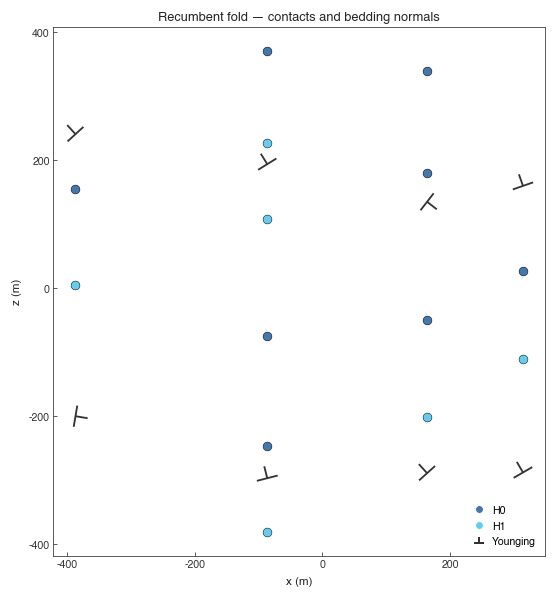

In [4]:
# Plot the data
colors = horizon_colors

fig, ax = plt.subplots(figsize=(5, 5))
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=colors, scatter_s=28, quiver_scale=0.025, legend=True,
)
figstyle.format_section_ax(ax, title="Recumbent fold — contacts and bedding normals")
fig.tight_layout()
plt.show()


## Constraints

A `CSet` is the geology we honour while fitting. An `HSet` (in the two
model sections below) is the loss weights.

- `gp`, `gv` — bedding-normal positions and vectors (`grad_loss`)
- `eq` — each horizon is an isosurface (`eq_loss`)
- `iq` — younger horizon below the older on restored depth. The group is `(H0, H1, "<")`: the hinge is on scalar(H0) − scalar(H1), so `"<"` asks for the younger scalar to lie below the older one (`iq_loss`).

Both models bind the same `C`.


In [5]:
# Stratigraphic order: scalar(H0) < scalar(H1), younger shallower on restored depth.
IQ_SAMPLES = 16
iq_pairs = [(horizons[0], horizons[1], "<")]

C = CSet(
    gp=gp,
    gv=gv,
    eq=horizons,
    iq=(IQ_SAMPLES, iq_pairs),
)
print(
    f"CSet: gp {gp.shape}, gv {gv.shape}, eq traces {len(horizons)}, "
    f"iq pairs {len(iq_pairs)}"
)

CSet: gp (8, 2), gv (8, 2), eq traces 2, iq pairs 1


## Evaluation grid

Predictions and the publication figure use the full 1.5 km box
(`step = 5` m), not a crop around the contacts. `G.coords()` is the tensor
both models are evaluated on.


In [6]:
# Evaluation Grid
dims = (1200, 1200)
G = Grid(dims, step=(5.0, 5.0), center=center, sampleArgs=dict(N=128))
domaxes = G.tformed_axes
domain = [np.array([domaxes[i].min(), domaxes[i].max()]) for i in range(len(domaxes))]
print("domain", domain)
# The same axes recumbent_inputs gives Surfe (01b).
assert all(np.allclose(a, b) for a, b in zip(domaxes, recumbent_inputs.grid_axes()))

domain [array([-600.,  595.]), array([-600.,  595.])]


## Truth (synthetic data)

With `DATASET = "synthetic"` the true units are known everywhere:
rebuild the fold from `01a`'s settings and evaluate it on the grid
(shifted back by `origin`). Units: 1 below `rock1` (oldest), 2 between the
contacts, 3 above `rock2` (youngest).

A fit's lithology IDs run 1–3 in isovalue order, which may be either
way round from the true units (the scalar can increase up or down), so
they are flipped when anti-correlated with the truth. Agreement is the
share of grid cells in the true unit, over the whole grid and per true
unit, as in the 3-D example. It is printed and saved with each fit
(`agreement`, `agreement_per_unit` in `nf.npz` and `ldi.npz`).

Whole-grid agreement mostly scores the extrapolation, where three holes decide
nothing, and barely notices a closed body. So each fit is also scored where the
data can decide the geometry (`recumbent_inputs.score_against_truth`, as in 01c
and 01d): the median distance between each fitted contact and the true one within the drillholes' window, and
each unit's intersection over union with the true one there (`contact_distance`,
`iou` in `nf.npz` and `ldi.npz`).

In [7]:
unit_true = None
N_UNITS = len(horizons) + 1
if DATASET == "synthetic":
    unit_true = recumbent_inputs.true_units(domaxes[0], domaxes[1], origin, DATA_DIR)
    print("true unit shares on the grid:",
          {int(u): round(float(np.mean(unit_true == u)), 3) for u in range(1, N_UNITS + 1)})


def match_units(litho):
    # Lithology IDs -> true units: flip the order if it runs against the truth.
    litho = np.asarray(litho, dtype=int)
    corr = np.corrcoef(litho.ravel(), unit_true.ravel())[0, 1]
    return N_UNITS + 1 - litho if corr < 0 else litho


def agreement(litho):
    unit = match_units(litho)
    return dict(volume=float(np.mean(unit == unit_true)),
                per_unit={u: float(np.mean(unit[unit_true == u] == u)) for u in range(1, N_UNITS + 1)})

true unit shares on the grid: {1: 0.392, 2: 0.224, 3: 0.385}


In [8]:
# Save the inputs and the evaluation grid. 01c_recumbent_fold_surfe reads this file,
# so Surfe is evaluated on exactly the grid used here.
np.savez_compressed(
    OUT_DIR / "inputs.npz",
    horizon_names=np.asarray(horizon_names),
    **{f"horizon_{i}": h for i, h in enumerate(horizons)},
    gp=gp, gv=gv,
    origin=origin,
    section_y=SECTION_Y,
    x=np.asarray(domaxes[0], dtype=float),
    z=np.asarray(domaxes[1], dtype=float),
    step=np.asarray([np.diff(a)[0] for a in domaxes], dtype=float),
    dataset=DATASET,
    **({"unit_true": unit_true} if unit_true is not None else {}),
)
print("wrote", OUT_DIR / "inputs.npz")

wrote results/synthetic/inputs.npz


## Implicit interpolant

`strati(..., type=FSF)` fits a scalar field ψ(*x*) directly to the contacts
and normals. Random Fourier features (`rff_features`, `length_scale_range`)
are the smoothness prior.

`HSet().zero(...)` turns every loss off except:

- `grad_loss` — bedding parallel to ∇ψ
- `eq_loss` — points on one horizon share a ψ value

`addIsosurface` names the contacts so `predict(..., litho=True)` can colour
lithology. This is the failure mode: without fold kinematics the overturned
limb is represented as a closed body.


In [9]:
# The Fourier basis, shared by NF and LDI: one wavelength band, mode count, direction count
# and seed, so both draw the same wavevectors and differ only in what the basis represents
# (NF: the scalar field; LDI: the velocity's stream function). The band is read off the data's
# spectral moments (curlew.priors.spectral.spectral_band): contacts give the variance of horizon
# heights, bedding the variance of slopes, neighbouring bedding the variance of curvatures.
# L_min is the shorter of the hinge spacing 2π√(m2/m4) and the limb spacing 2π√(m0/m2); L_max
# the longer, and at least two octaves above L_min and the data's diameter. The mode count
# follows from the band at a fixed number of modes per octave.
MODES_PER_OCTAVE = 128
N_DIRECTIONS = 32
FOURIER_SEED = 42
LSR, BAND_INFO = spectral_band(C, return_info=True)
N_FEATURES = n_features_for_band(LSR, MODES_PER_OCTAVE, N_DIRECTIONS)
LSR_NF = LSR_LDI = LSR
N_FEATURES_LDI = N_FEATURES
print(f"band {LSR[0]:.0f}-{LSR[1]:.0f} m | M {N_FEATURES} |", BAND_INFO)

# NF parameters
EPOCHS_NF = 3000
LR_ADAM_NF = 5e-2

# Implicit interpolant: fit a scalar field directly to contacts and normals
H_implicit = HSet().zero(grad_loss="1e0", eq_loss="1e-1")

event_implicit = strati(
    "recumbent_fold_implicit",
    type=FSF,
    activation="cubic",
    rff_features=N_FEATURES,
    n_directions = N_DIRECTIONS,
    length_scale_range=LSR_NF,
    seed=FOURIER_SEED,
    C=C,
    freq_damp=0.,
    H=H_implicit,
    learning_rate=LR_ADAM_NF,
)

for name, h in zip(reversed(horizon_names), reversed(horizons)):
    event_implicit.addIsosurface(name, seed=h)

model_implicit = curlew.GeoModel([event_implicit])

/Users/kamath92/anaconda3/envs/curlew_dev/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3701: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/kamath92/Documents/Work/2026/DevOps/curlew/curlew/priors/spectral.py:790: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  mom = spectral_moments(data, axis=axis)
/Users/kamath92/Documents/Work/2026/DevOps/curlew/curlew/priors/spectral.py:660: UserWarning: spectral_moments could not resolve λx from curvature pairs; using nearest-neighbour fallback (lambda_x may be biased high).
  _warn_moment_quality(pick, stacklevel=2)


band 987-3949 m | M 256 | {'m0': None, 'm2': 1.3544707255474664, 'm4': 5.484921392403393e-05, 'lambda_x': 987.3689731521758, 'lambda_0': None, 'normal': [-0.26142865581734426, 0.9652228022159116], 'normal_from_contacts': False, 'resolved': False, 'lambda_x_error': None, 'n_curvature': 9.529411764705882, 'window': None, 'contact_noise': None, 'n_eff': 1.0000000000000002, 'n_bedding': 8, 'n_contacts': 14, 'n_pairs': 10, 'n_windows': 0, 'n_horizons_spanning': 0, 'profile': False, 'diameter': 1027.7482096227357, 'strain': None}


In [10]:
# Fit the implicit interpolant
pebble_implicit = model_implicit.prefit(epochs=EPOCHS_NF, best=True, vb=True, early_stop=None)

L=0.000 grad_loss=0.000 eq_loss=0.000: : 3000/3000|


In [11]:
# Evaluate the implicit interpolant
grd = torch.tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
with torch.no_grad():
    geode_implicit = model_implicit.predict(grd, litho=True)

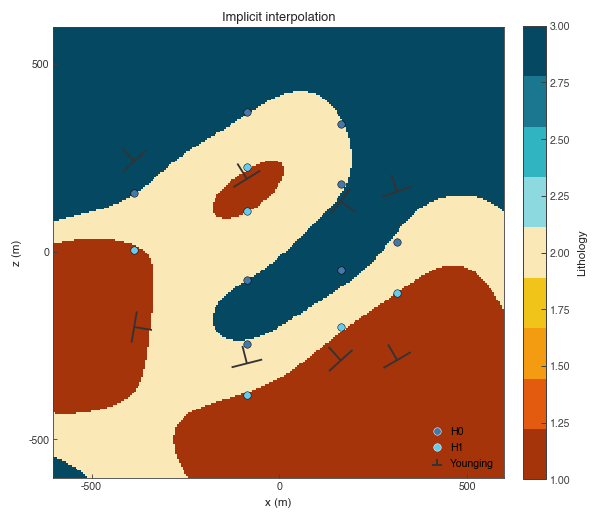

In [12]:
# Diagnostic: implicit lithology
fig, ax = plt.subplots(figsize=(5, 5))
m = ax.pcolormesh(
    domaxes[0], domaxes[1],
    G.reshape(geode_implicit.lithoID).T,
    cmap=curlew.ccmap, shading="auto",
)
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=colors, scatter_s=20, quiver_scale=0.01, legend=True,
)
figstyle.format_section_ax(ax, title="Implicit interpolation")
figstyle.add_colorbar(fig, m, ax, "Lithology")
fig.tight_layout()
plt.show()


## Restore

`restore` does not interpolate ψ in present-day coordinates. A Euler
velocity *v* (`div v = 0`, `stream="alpha"`) is integrated to a
diffeomorphism Φ. The scalar is the spectral layer cake carried by the
inverse map, ψ(*x*) = *n* · (Φ⁻¹ *x*), where *n* is the unit vector along the depth axis
(`depth_axis=1`, the default flat layer cake). Bedding is matched after Nanson transport through Φ.

The same `C` is used. Losses are again gradient and equality, now evaluated
in the restored frame. `pin` holds the origin fixed. Integration is the
Quispel–McLaren shear splitting (`integrator="shear"`): each trigonometric
term is an exact translation, Strang-swept `n_steps` times.


In [ ]:
# LDI parameters. The basis (LSR_LDI, N_FEATURES_LDI, N_DIRECTIONS, FOURIER_SEED) is the one
# set above for NF.
EPOCHS_LDI = 2000
N_STEPS = 0
INTEGRATOR = "shear"
LR_ADAM = 5e-3            # now the Adam rate for phase/bias
LR_SGD = 1e-1             # SGD rate for amplitudes: the one new knob
INIT_STD = 0

velocity = euler_velocity(
    2,
    n_features=N_FEATURES_LDI,
    n_directions=N_DIRECTIONS,
    seed=FOURIER_SEED,
    length_scale_range=LSR_LDI,
    stream="alpha",
    activation="cubic",
    energy_normalised=True,          # NEW: C carries all the energy; bias/phi only change shape
)

H_restore = HSet().zero(grad_loss="1e0", eq_loss="1e-1")   # unchanged: no energy_loss

event_restore = restore(
    "recumbent_fold_restore",
    C=C,
    H=H_restore,
    velocity=velocity,
    n_steps=N_STEPS,
    integrator=INTEGRATOR,
    depth_axis=1,
    init_std=INIT_STD,
    sigma_floor=0.0,
    signed_normals=True,
    learning_rate=LR_ADAM,
    optimizer={                       # NEW
        "amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=0.9, nesterov=True)),
        "shape": (torch.optim.Adam, dict(lr=LR_ADAM)),
    },
    pin=anchor,
)

for name, h in zip(reversed(horizon_names), reversed(horizons)):
    event_restore.addIsosurface(name, seed=h)

model_restore = curlew.GeoModel([event_restore])
assert isinstance(event_restore.field.velocity, EulerVelocity)
print(
    f"restore velocity: {type(event_restore.field.velocity).__name__}, "
    f"n_steps={N_STEPS}, integrator={event_restore.field.integrator.integrator}"
)

restore velocity: EulerVelocity, n_steps=0, integrator=shear


In [14]:
# Fit the restore event
# Spectral warm-up (curlew.kinematics.training.SpectralWarmup): the octaves of the band are let in from
# the longest to the shortest, so the long modes build the fold and the short ones only refine it.
SPECTRAL_WARMUP = False
with SpectralWarmup(event_restore) as schedule:   # octaves open over the first 1/6 of the epochs
    pebble_restore = model_restore.prefit(epochs=EPOCHS_LDI, vb=True, early_stop=None,
                                          schedule=schedule if SPECTRAL_WARMUP else None)

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2000/2000|


In [15]:
# Evaluate restore lithology, scalar field, and inverted velocity v = Φ̇ (present → restored)
with torch.no_grad():
    geode_restore = model_restore.predict(grd, litho=True)
    vel_restore = event_restore.field.velocity(grd)

vel_np = vel_restore.detach().cpu().numpy()
print(
    f"restore litho unique={np.unique(np.asarray(geode_restore.lithoID))}, "
    f"|v| p50={np.median(np.linalg.norm(vel_np, axis=-1)):.2f} "
    f"p99={np.percentile(np.linalg.norm(vel_np, axis=-1), 99):.2f}"
)

restore litho unique=[1 2 3], |v| p50=373.70 p99=839.10


## Visual check

Six panels, full grid extent — a quick look at the fits. With synthetic data
the true contacts are dashed on the scalar and lithology panels. This figure is not
saved; the publication version is made from the saved results in
`01e_recumbent_fold_figures.ipynb`.

implicit gradient extrema: maxima=1, minima=3, saddles=3
restore gradient extrema: maxima=0, minima=0, saddles=0
paleo lines: 67 horiz × 67 vert, 501 samples/line


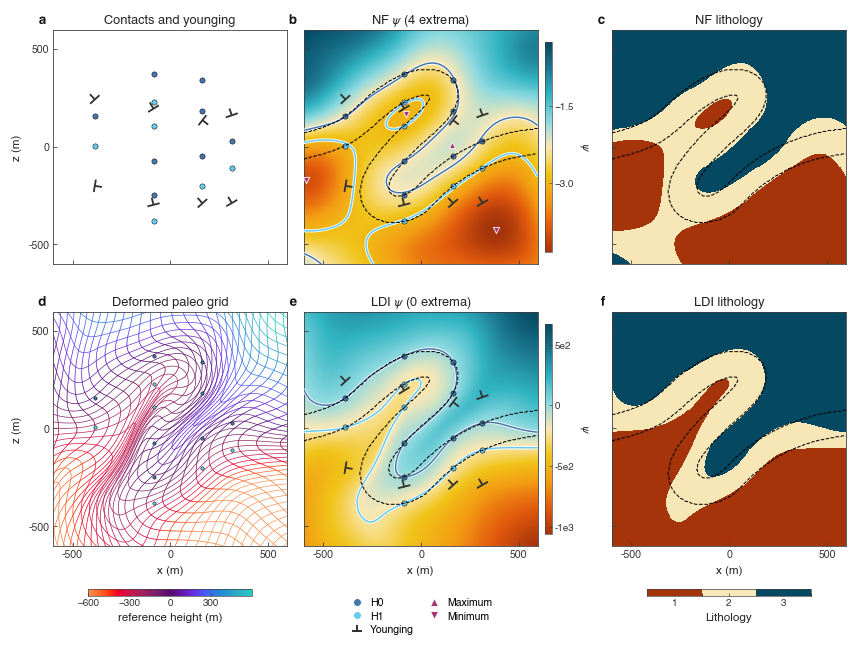

In [16]:
# Visual check (not saved): implicit interpolant vs restore
import importlib
importlib.reload(figstyle)
importlib.reload(diagnostics)
figstyle.apply()

litho_i = np.asarray(G.reshape(geode_implicit.lithoID))
litho_r = np.asarray(G.reshape(geode_restore.lithoID))
sf_i = np.asarray(G.reshape(geode_implicit.scalar), dtype=float)
sf_r = np.asarray(G.reshape(geode_restore.scalar), dtype=float)
# The isovalues curlew classified the lithology with (mean field at each horizon's contacts),
# so the contact lines bound the units.
iso_i = [event_implicit.getIsovalue(n) for n in horizon_names]
iso_r = [event_restore.getIsovalue(n) for n in horizon_names]

crit_i = diagnostics.find_critical_points(event_implicit, domaxes[0], domaxes[1])
crit_r = diagnostics.find_critical_points(event_restore, domaxes[0], domaxes[1])
print(
    f"implicit gradient extrema: maxima={crit_i.counts['maximum']}, "
    f"minima={crit_i.counts['minimum']}, saddles={crit_i.counts['saddle']}"
)
print(
    f"restore gradient extrema: maxima={crit_r.counts['maximum']}, "
    f"minima={crit_r.counts['minimum']}, saddles={crit_r.counts['saddle']}"
)

litho_ids = np.unique(np.concatenate([litho_i.ravel(), litho_r.ravel()]))
cmap_litho, norm_litho = figstyle.litho_cmap(litho_ids)
xlim = (float(domaxes[0][0]), float(domaxes[0][-1]))
zlim = (float(domaxes[1][0]), float(domaxes[1][-1]))
extent = (*xlim, *zlim)

# Material grid in the restored frame: bedding at constant reference height n·x (n is the flat
# reference's normal, the unit vector along the depth axis),
# columns along n. Coloured by that height, then pushed into the present.
from matplotlib.collections import LineCollection

n_along = 501
line_dx = 50.0
pad = 1050.0
xmin, xmax = xlim[0] - pad, xlim[1] + pad
zmin, zmax = zlim[0] - pad, zlim[1] + pad
n_hat = np.zeros(2)
n_hat[event_restore.field.depth_axis] = 1.0   # flat layer cake: ψ = x[depth_axis]
tangent = np.array([-n_hat[1], n_hat[0]])
corners = np.array([[xmin, zmin], [xmin, zmax], [xmax, zmin], [xmax, zmax]])
along_n = corners @ n_hat
along_t = corners @ tangent
z_lines = np.arange(along_n.min(), along_n.max() + 0.5 * line_dx, line_dx)
x_lines = np.arange(along_t.min(), along_t.max() + 0.5 * line_dx, line_dx)
u = np.linspace(along_t.min(), along_t.max(), n_along)
s_z = np.linspace(along_n.min(), along_n.max(), n_along)
horiz = np.stack([s * n_hat + u[:, None] * tangent for s in z_lines], axis=0)
vert = np.stack([c * tangent + s_z[:, None] * n_hat for c in x_lines], axis=0)
paleo = torch.tensor(
    np.concatenate([horiz.reshape(-1, 2), vert.reshape(-1, 2)], axis=0),
    dtype=curlew.dtype,
    device=curlew.device,
)
n_h, n_v = len(z_lines), len(x_lines)
flow = event_restore.field.integrator


@torch.no_grad()
def push_paleo(y, t):
    t = float(t)
    if t <= 0.0:
        return y.detach().cpu().numpy()
    return flow.map_to_time(y + flow.frame_offset, t, forward=True).detach().cpu().numpy()


def split_grid(pts):
    h_pts = pts[: n_h * n_along].reshape(n_h, n_along, 2)
    v_pts = pts[n_h * n_along :].reshape(n_v, n_along, 2)
    return h_pts, v_pts


def draw_grid(ax, pts, *, lw):
    h_pts, v_pts = split_grid(pts)
    for line, col in zip(h_pts, h_colors):
        ax.plot(line[:, 0], line[:, 1], color=col, lw=lw, solid_capstyle="round", zorder=2)
    for line in v_pts:
        segs = np.stack([line[:-1], line[1:]], axis=1)
        ax.add_collection(LineCollection(
            segs, colors=v_colors, linewidths=lw, capstyle="round", zorder=2,
        ))


window = np.array([[xlim[0], zlim[0]], [xlim[0], zlim[1]], [xlim[1], zlim[0]], [xlim[1], zlim[1]]])
wn = window @ n_hat
norm_z = Normalize(vmin=float(wn.min()), vmax=float(wn.max()))
h_colors = cmr.guppy(norm_z(z_lines))
v_colors = cmr.guppy(norm_z(0.5 * (s_z[:-1] + s_z[1:])))
sm_z = plt.cm.ScalarMappable(norm=norm_z, cmap=cmr.guppy)
sm_z.set_array([])
present_grid = push_paleo(paleo, 1.0)
print(f"paleo lines: {n_h} horiz × {n_v} vert, {n_along} samples/line")

# Columns a/d and c/f lose their vertical colour-bar slots (those bars go
# below the figure), and the grid gives that width to the maps.
fig, grid = figstyle.comparison_grid(2, 3, xlim=xlim, zlim=zlim)


def _field(ax, field, cmap, **kw):
    return ax.imshow(
        np.asarray(field).T, origin="lower", extent=extent, cmap=cmap,
        interpolation="nearest", aspect="equal", rasterized=True, **kw,
    )


# Top row — Data and Implicit Interpolation
ax = grid[0]
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=horizon_colors, scatter_s=10, quiver_scale=0.013,
)
figstyle.format_section_ax(ax, xlabel=False, title="Contacts and younging")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[0])

ax = grid[1]
im_sfi = _field(ax, sf_i, curlew.ccramp)
figstyle.draw_contact_contours(ax, domaxes[0], domaxes[1], sf_i, horizons, horizon_names, colors=horizon_colors, levels=iso_i)
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=horizon_colors, scatter_s=10, quiver_scale=0.013,
)
figstyle.format_section_ax(ax, xlabel=False, ylabel=False, title=diagnostics.extrema_title("NF", crit_i))
figstyle.set_view(ax, xlim, zlim)
figstyle.add_cbar(grid.cbar_axes[1], im_sfi, r"$\psi$")
diagnostics.overlay_critical_points(ax, crit_i, size=14)

ax = grid[2]
im_litho = _field(ax, litho_i, cmap_litho, norm=norm_litho)
figstyle.format_section_ax(ax, xlabel=False, ylabel=False, title="NF lithology")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[2])

# Bottom row — Geometric restoration
ax = grid[3]
draw_grid(ax, present_grid, lw=0.4)
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=horizon_colors, scatter_s=4, show_quiver=False,
)
figstyle.format_section_ax(ax, title="Deformed paleo grid")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[3])

ax = grid[4]
im_sfr = _field(ax, sf_r, curlew.ccramp)
figstyle.draw_contact_contours(ax, domaxes[0], domaxes[1], sf_r, horizons, horizon_names, colors=horizon_colors, levels=iso_r)
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors=horizon_colors, scatter_s=10, quiver_scale=0.013,
)
figstyle.format_section_ax(ax, ylabel=False, title=diagnostics.extrema_title("LDI", crit_r))
figstyle.set_view(ax, xlim, zlim)
figstyle.add_cbar(grid.cbar_axes[4], im_sfr, r"$\psi$")
diagnostics.overlay_critical_points(ax, crit_r, size=14)

ax = grid[5]
_field(ax, litho_r, cmap_litho, norm=norm_litho)
figstyle.format_section_ax(ax, ylabel=False, title="LDI lithology")
figstyle.set_view(ax, xlim, zlim)
figstyle.hide_cbar(grid.cbar_axes[5])

# The true contacts (dashed), with synthetic data.
if unit_true is not None:
    for ax in (grid[1], grid[2], grid[4], grid[5]):
        ax.contour(domaxes[0], domaxes[1], unit_true.T, levels=[1.5, 2.5],
                   colors="k", linestyles="--", linewidths=0.6, zorder=6)

for ax, letter in zip(grid.axes, "abcdef"):
    figstyle.panel_label(ax, letter)

legend_handles = (
    figstyle.constraint_handles(horizon_colors, horizon_names)
    + diagnostics.extrema_handles(crit_i, crit_r)
)
# Bottom band, tops level: paleo-z colour bar under d, legend under e, and one
# lithology colour bar under f (c and f share the classes).
figstyle.bottom_cbar(grid.axes[3], sm_z, r"reference height (m)")
figstyle.bottom_cbar(grid.axes[5], im_litho, "Lithology", ticks=litho_ids)
figstyle.bottom_legend(grid.axes[4], legend_handles, ncol=2)

plt.show()


In [17]:
# Agreement with the true units (synthetic data only).
scores, geometry = {}, {}
if unit_true is not None:
    truth = recumbent_inputs.truth_reference(origin, DATA_DIR)
    for label, litho in (("NF", litho_i), ("LDI", litho_r)):
        scores[label] = agreement(litho)
        geometry[label] = recumbent_inputs.score_against_truth(match_units(litho), domaxes[0], domaxes[1],
                                                               unit_true, truth)
        g = geometry[label]
        print(f"{label}: agreement {100 * scores[label]['volume']:.1f}%; per true unit "
              + ", ".join(f"{u}: {100 * a:.1f}%" for u, a in scores[label]["per_unit"].items()))
        print(f"     within x {np.round(truth['window'])} m: "
              "contact distance " + ", ".join(f"{n} {v:.1f} m" for n, v in zip(horizon_names, g["contact_distance"]))
              + "; IoU per unit " + ", ".join(f"{v:.2f}" for v in g["iou"]))


def score_arrays(label):
    if label not in scores:
        return {}
    g = geometry[label]
    return {"agreement": scores[label]["volume"],
            "agreement_per_unit": np.asarray(list(scores[label]["per_unit"].values())),
            "contact_distance": np.asarray(g["contact_distance"]),
            "iou": np.asarray(g["iou"])}


# Save the single-fit results used by the publication figures.
np.savez_compressed(
    OUT_DIR / "nf.npz",
    scalar=sf_i.astype(np.float32),
    lithology=litho_i.astype(np.int8),
    isovalues=np.asarray(iso_i),
    **score_arrays("NF"),
    **diagnostics.pack_critical(crit_i),
)
np.savez_compressed(
    OUT_DIR / "ldi.npz",
    scalar=sf_r.astype(np.float32),
    lithology=litho_r.astype(np.int8),
    isovalues=np.asarray(iso_r),
    present_grid=present_grid.astype(np.float32),
    z_lines=z_lines, s_z=s_z, n_along=n_along,
    **score_arrays("LDI"),
    **diagnostics.pack_critical(crit_r),
)
# Fitted field parameters, so the models ship with the paper.
torch.save(event_implicit.field.state_dict(), OUT_DIR / "nf_field.pt")
torch.save(event_restore.field.state_dict(), OUT_DIR / "ldi_field.pt")
# The fit settings, so the Fourier-seed ensemble (01d) fits its members exactly the same way.
import json
(OUT_DIR / "fit_settings.json").write_text(json.dumps(dict(
    lsr_nf=list(LSR_NF), lsr_ldi=list(LSR_LDI), n_features=N_FEATURES, n_features_ldi=N_FEATURES_LDI,
    modes_per_octave=MODES_PER_OCTAVE, band_info=BAND_INFO,
    n_directions=N_DIRECTIONS, fourier_seed=FOURIER_SEED,
    depth_axis=int(event_restore.field.depth_axis),
    iq_samples=IQ_SAMPLES, weights=dict(grad_loss="1e0", eq_loss="1e-1"),
    epochs_nf=EPOCHS_NF, epochs_ldi=EPOCHS_LDI, n_steps=N_STEPS, integrator=INTEGRATOR,
    lr_adam_nf=LR_ADAM_NF, nf_freq_damp=0.0,
    lr_adam=LR_ADAM, init_std=INIT_STD,
    energy_normalised=True,
    lr_sgd=LR_SGD, amp_momentum=0.9, spectral_warmup=SPECTRAL_WARMUP, warmup_ramp=schedule.ramp,
), indent=2))
print("wrote nf.npz, ldi.npz, nf_field.pt, ldi_field.pt, fit_settings.json to", OUT_DIR)

NF: agreement 86.4%; per true unit 1: 77.4%, 2: 88.9%, 3: 94.2%
     within x [-503.  430.] m: contact distance H0 13.6 m, H1 14.5 m; IoU per unit 0.73, 0.63, 0.91
LDI: agreement 92.9%; per true unit 1: 93.2%, 2: 84.9%, 3: 97.2%
     within x [-503.  430.] m: contact distance H0 4.7 m, H1 13.6 m; IoU per unit 0.88, 0.78, 0.96
wrote nf.npz, ldi.npz, nf_field.pt, ldi_field.pt, fit_settings.json to results/synthetic
